In [21]:
import pandas as pd

df = pd.read_csv("data/raw/student_mental_health.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [22]:
df["Physical_Activity"].unique()

array(['Moderate', 'Low', 'High'], dtype=object)

In [23]:
#Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Mental_Health_Risk", "Student_ID"])

y = df["Mental_Health_Risk"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
#Traiter les valeurs manquantes en choisissant la méthode d’imputation la plus adaptée à la nature des données
numeric_features = [
    "Age",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate"
]

categorical_features = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

In [25]:

from sklearn.impute import SimpleImputer

imputer_numeric = SimpleImputer(strategy="median")


In [ ]:
imputer_categoriel =SimpleImputer(strategy="most_frequent")

In [26]:
#Détecter et traiter les valeurs aberrantes en utilisant une méthode appropriée IQR
for col in numeric_features:
    Q1 =X_train[col].quantile(0.25)
    Q3 =X_test[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    Upper =Q3 + 1.5 * IQR
    
    outliers = X_train[
        (X_train[col] < lower) |
        (X_train[col] > Upper)
    ]
    
    print(f"{col} :   {len(outliers)} valeurs aberrantes")

Age :   42 valeurs aberrantes
Year_of_Study :   0 valeurs aberrantes
Sleep_Hours :   1 valeurs aberrantes
Study_Hours_Per_Week :   8 valeurs aberrantes
GPA :   11 valeurs aberrantes
Social_Media_Hours :   16 valeurs aberrantes
Screen_Time_Hours :   11 valeurs aberrantes
Financial_Stress :   0 valeurs aberrantes
Family_Support :   0 valeurs aberrantes
Attendance_Rate :   11 valeurs aberrantes


In [ ]:
#Encoder les variables catégorielles afin de les convertir en valeurs numériques
from sklearn.preprocessing import OneHotEncoder
nominal_features = [
    "Gender",
    "Part_Time_Job",
    "Previous_Mental_Health_History"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_features = [
    "Physical_Activity",
    "Diet_Quality"
]

ordinal_encoder =OrdinalEncoder(
    categories=[
        ["Low", "Medium", "High"],
        ["Poor", "Average", "Good"] 
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)


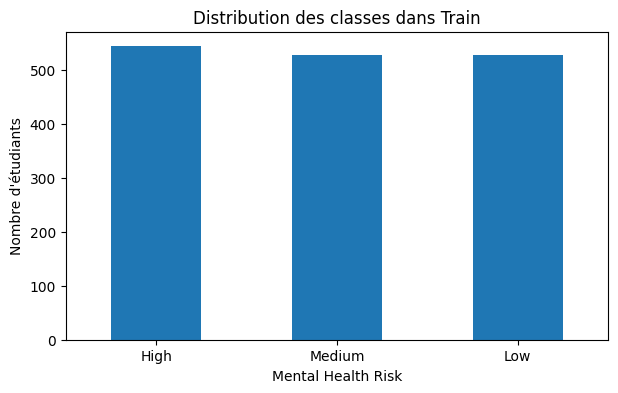

In [27]:
import matplotlib.pyplot as plt

y_train.value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Distribution des classes dans Train"
)

plt.xlabel("Mental Health Risk")
plt.ylabel("Nombre d'étudiants")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Standardiser les variables numériques
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [31]:
#Construire le preprocessing Pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Pipeline des variables numériques
numeric_pipeline = Pipeline([
    ("Imputer",SimpleImputer(strategy="mean")),
    ("scaler",StandardScaler())
])

# Pipeline des variables nominales
nominal_pipeline =Pipeline([
    ("Imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])

# Pipeline des variables ordinales
ordinal_pipeline =Pipeline([
    ("Imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OrdinalEncoder(
        categories=[
            ["Low", "Moderate", "High"],
            ["Poor", "Average", "Good"]
        ],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])


preprocessor = ColumnTransformer([
    ("numeric",numeric_pipeline ,numeric_features),
    ("nominal",nominal_pipeline ,nominal_features),
    ("ordinal",ordinal_pipeline ,ordinal_features)
])

In [32]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

In [33]:
import os

os.makedirs("data/processed", exist_ok=True)

X_train_processed_df = pd.DataFrame(X_train_processed)
X_test_processed_df = pd.DataFrame(X_test_processed)

X_train_processed_df.to_csv("data/processed/X_train.csv", index=False)
X_test_processed_df.to_csv("data/processed/X_test.csv", index=False)

y_train.to_csv("data/processed/y_train.csv", index=False)
y_test.to_csv("data/processed/y_test.csv", index=False)